In [4]:
import sys
print(sys.executable)

c:\Users\VISHALI\AppData\Local\Python\pythoncore-3.14-64\python.exe


In [5]:
import pandas as pd
print("Pandas version:", pd.__version__)

Pandas version: 3.0.5


In [6]:
from pathlib import Path
import pandas as pd

BASE_DIR = Path.cwd().parent
DATA_PATH = BASE_DIR / "dataset" / "MRTSSM44000USS.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (416, 2)

First 5 rows:


,observation_date,MRTSSM44000USS
0,1992-01-01,142419
1,1992-02-01,142584
2,1992-03-01,142120
3,1992-04-01,143659
4,1992-05-01,144239



Column names:
['observation_date', 'MRTSSM44000USS']


In [7]:
print("Dataset shape:", df.shape)

print("\nColumn names and data types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nLast 5 rows:")
display(df.tail())

Dataset shape: (416, 2)

Column names and data types:
observation_date      str
MRTSSM44000USS      int64
dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 416 entries, 0 to 415
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   observation_date  416 non-null    str  
 1   MRTSSM44000USS    416 non-null    int64
dtypes: int64(1), str(1)
memory usage: 6.6 KB

Last 5 rows:


,observation_date,MRTSSM44000USS
411,2026-04-01,635221
412,2026-05-01,641883
413,2026-06-01,642793
414,2026-07-01,639263
415,2026-08-01,647440


In [8]:
# Convert the date column to datetime
df["observation_date"] = pd.to_datetime(df["observation_date"])

# Rename the sales column
df = df.rename(columns={
    "observation_date": "date",
    "MRTSSM44000USS": "sales"
})

# Sort records by date
df = df.sort_values("date").reset_index(drop=True)

# Display the cleaned dataset
display(df.head())

print("Data types:")
print(df.dtypes)

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

print("\nMissing values:")
print(df.isnull().sum())

,date,sales
0,1992-01-01,142419
1,1992-02-01,142584
2,1992-03-01,142120
3,1992-04-01,143659
4,1992-05-01,144239


Data types:
date     datetime64[us]
sales             int64
dtype: object

Date range:
1992-01-01 00:00:00 to 2026-08-01 00:00:00

Missing values:
date     0
sales    0
dtype: int64


In [9]:
print(df.columns.tolist())

['date', 'sales']


In [10]:
print("Data types:")
print(df.dtypes)

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst 5 rows:")
display(df.head())

Data types:
date     datetime64[us]
sales             int64
dtype: object

Date range:
1992-01-01 00:00:00 to 2026-08-01 00:00:00

Missing values:
date     0
sales    0
dtype: int64

First 5 rows:


,date,sales
0,1992-01-01,142419
1,1992-02-01,142584
2,1992-03-01,142120
3,1992-04-01,143659
4,1992-05-01,144239


In [11]:
print("Data types:")
print(df.dtypes)

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

print("\nMissing values:")
print(df.isnull().sum())

print("\nNumber of duplicate dates:")
print(df["date"].duplicated().sum())

Data types:
date     datetime64[us]
sales             int64
dtype: object

Date range:
1992-01-01 00:00:00 to 2026-08-01 00:00:00

Missing values:
date     0
sales    0
dtype: int64

Number of duplicate dates:
0


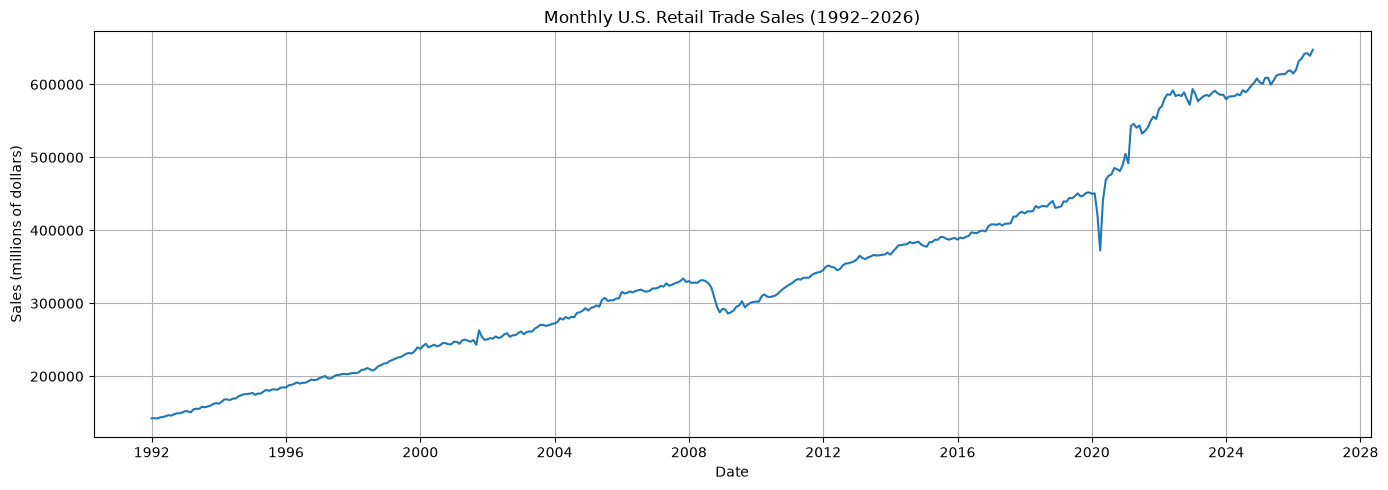

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(df["date"], df["sales"])

plt.title("Monthly U.S. Retail Trade Sales (1992–2026)")
plt.xlabel("Date")
plt.ylabel("Sales (millions of dollars)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [13]:
# Calculate the change in sales from the previous month
df["monthly_change"] = df["sales"].diff()

# Calculate the percentage change from the previous month
df["monthly_pct_change"] = df["sales"].pct_change() * 100

print("Largest monthly increase:")
display(df.loc[df["monthly_change"].idxmax()])

print("\nLargest monthly decrease:")
display(df.loc[df["monthly_change"].idxmin()])

print("\nSummary of monthly percentage changes:")
display(df["monthly_pct_change"].describe().round(2))

Largest monthly increase:


date                  2020-05-01 00:00:00
sales                              441263
monthly_change                    68882.0
monthly_pct_change              18.497721
Name: 340, dtype: object


Largest monthly decrease:


date                  2020-04-01 00:00:00
sales                              372381
monthly_change                   -50441.0
monthly_pct_change             -11.929606
Name: 339, dtype: object


Summary of monthly percentage changes:


count    415.00
mean       0.38
std        1.65
min      -11.93
25%       -0.15
50%        0.39
75%        0.94
max       18.50
Name: monthly_pct_change, dtype: float64

In [14]:
# Reserve the latest 12 months for testing
test_size = 12

train = df.iloc[:-test_size].copy()
test = df.iloc[-test_size:].copy()

print("Training period:")
print(train["date"].min(), "to", train["date"].max())

print("\nTesting period:")
print(test["date"].min(), "to", test["date"].max())

print("\nTraining records:", len(train))
print("Testing records:", len(test))

Training period:
1992-01-01 00:00:00 to 2025-08-01 00:00:00

Testing period:
2025-09-01 00:00:00 to 2026-08-01 00:00:00

Training records: 404
Testing records: 12


In [15]:
# Use the last training month's sales as the forecast for every test month
baseline_value = train["sales"].iloc[-1]

baseline_forecast = test[["date", "sales"]].copy()
baseline_forecast["baseline_prediction"] = baseline_value

print("Latest training sales:", baseline_value)

display(baseline_forecast)

Latest training sales: 613570


,date,sales,baseline_prediction
404,2025-09-01,614111,613570
405,2025-10-01,613900,613570
406,2025-11-01,618029,613570
407,2025-12-01,619122,613570
408,2026-01-01,614871,613570
409,2026-02-01,620373,613570
410,2026-03-01,631907,613570
411,2026-04-01,635221,613570
412,2026-05-01,641883,613570
413,2026-06-01,642793,613570


In [16]:
import numpy as np

actual = baseline_forecast["sales"].to_numpy()
predicted = baseline_forecast["baseline_prediction"].to_numpy()

errors = actual - predicted

baseline_mae = np.mean(np.abs(errors))
baseline_rmse = np.sqrt(np.mean(errors ** 2))

print("Baseline MAE:", round(baseline_mae, 2))
print("Baseline RMSE:", round(baseline_rmse, 2))

Baseline MAE: 14672.75
Baseline RMSE: 19076.62


In [17]:

from statsmodels.tsa.holtwinters import Holt

print("Holt forecasting model is ready!")

Holt forecasting model is ready!


In [18]:
import sys
print(sys.executable)

c:\Users\VISHALI\AppData\Local\Python\pythoncore-3.14-64\python.exe


In [19]:
import sys
print(sys.executable)
print("Python kernel is working!")

c:\Users\VISHALI\AppData\Local\Python\pythoncore-3.14-64\python.exe
Python kernel is working!


In [20]:
from statsmodels.tsa.holtwinters import Holt

print("Holt forecasting model is ready!")

Holt forecasting model is ready!


In [21]:
# Recreate the training and testing split
test_size = 12

train = df.iloc[:-test_size].copy()
test = df.iloc[-test_size:].copy()

print("Training records:", len(train))
print("Testing records:", len(test))
print("Latest training date:", train["date"].max())
print("Latest testing date:", test["date"].max())

Training records: 404
Testing records: 12
Latest training date: 2025-08-01 00:00:00
Latest testing date: 2026-08-01 00:00:00


In [27]:
sales_train = train["sales"].to_numpy(dtype=float)

holt_model = Holt(
    sales_train,
    initialization_method="estimated"
).fit(optimized=True)

holt_predictions = holt_model.forecast(len(test))

holt_forecast = test[["date", "sales"]].copy()
holt_forecast["holt_prediction"] = holt_predictions

display(holt_forecast)

,date,sales,holt_prediction
404,2025-09-01,614111,614605.906610
405,2025-10-01,613900,615776.001968
406,2025-11-01,618029,616946.097326
407,2025-12-01,619122,618116.192684
408,2026-01-01,614871,619286.288042
409,2026-02-01,620373,620456.383399
410,2026-03-01,631907,621626.478757
411,2026-04-01,635221,622796.574115
412,2026-05-01,641883,623966.669473
413,2026-06-01,642793,625136.764831


In [23]:
print("Training data type:", type(train))
print("Sales column type:", train["sales"].dtype)
print("Training data shape:", train.shape)
print("Missing sales values:", train["sales"].isnull().sum())

import statsmodels
print("Statsmodels version:", statsmodels.__version__)

Training data type: <class 'pandas.DataFrame'>
Sales column type: int64
Training data shape: (404, 4)
Missing sales values: 0
Statsmodels version: 0.15.0


In [26]:
import inspect
from statsmodels.tsa.holtwinters import Holt

print("Holt function signature:")
print(inspect.signature(Holt))

print("\nHolt class module:")
print(Holt.__module__)

print("\nHolt docstring:")
print(Holt.__doc__[:500])

Holt function signature:
(endog, exponential=False, damped_trend=False, initialization_method=None, initial_level=None, initial_trend=None)

Holt class module:
statsmodels.tsa.holtwinters.model

Holt docstring:

Holt's Exponential Smoothing

Parameters
----------
endog : array_like
    The time series to model.
exponential : bool, optional
    Type of trend component.
damped_trend : bool, optional
    Should the trend component be damped.
initialization_method : str, optional
    Method for initialize the recursions. One of:

    * None
    * 'estimated'
    * 'heuristic'
    * 'legacy-heuristic'
    * 'known'

    None defaults to the pre-0.12 behavior where initial values
    are passed as part of ``


In [28]:
import numpy as np

actual = holt_forecast["sales"].to_numpy(dtype=float)
predicted = holt_forecast["holt_prediction"].to_numpy(dtype=float)

holt_errors = actual - predicted

holt_mae = np.mean(np.abs(holt_errors))
holt_rmse = np.sqrt(np.mean(holt_errors ** 2))

print("Holt MAE:", round(holt_mae, 2))
print("Holt RMSE:", round(holt_rmse, 2))

print("\nBaseline MAE:", round(baseline_mae, 2))
print("Baseline RMSE:", round(baseline_rmse, 2))

Holt MAE: 8346.25
Holt RMSE: 11122.9

Baseline MAE: 14672.75
Baseline RMSE: 19076.62


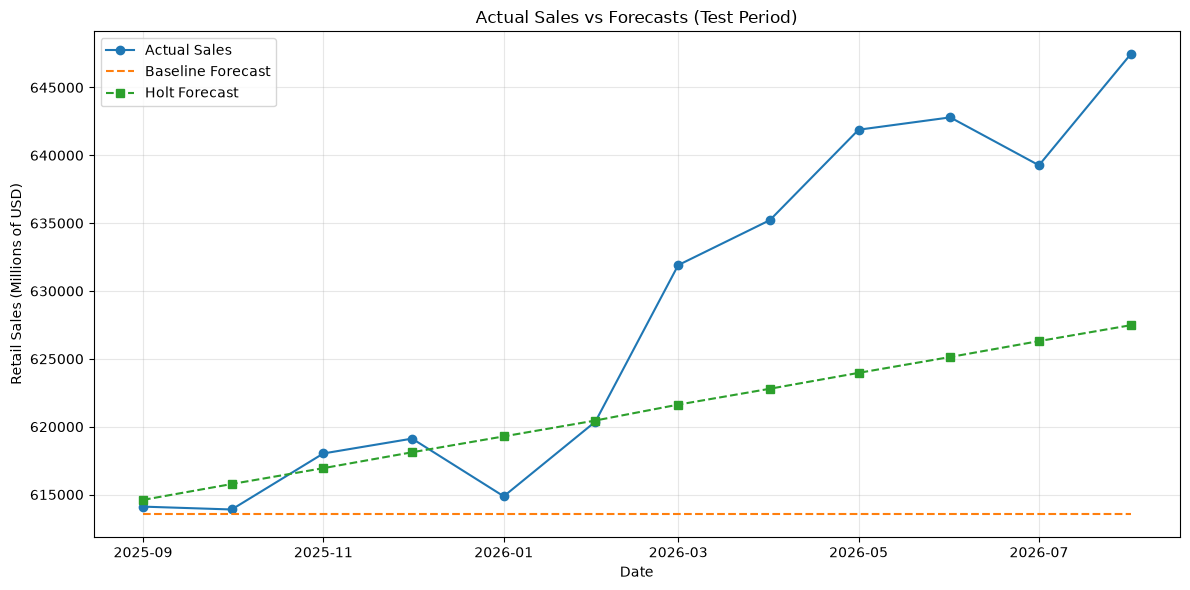

In [35]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    holt_forecast["date"],
    holt_forecast["sales"],
    marker="o",
    label="Actual Sales"
)

ax.plot(
    baseline_forecast["date"],
    baseline_forecast["baseline_prediction"],
    linestyle="--",
    label="Baseline Forecast"
)

ax.plot(
    holt_forecast["date"],
    holt_forecast["holt_prediction"],
    linestyle="--",
    marker="s",
    label="Holt Forecast"
)

ax.set_title("Actual Sales vs Forecasts (Test Period)")
ax.set_xlabel("Date")
ax.set_ylabel("Retail Sales (Millions of USD)")
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(
    BASE_DIR / "visualizations" / "actual_vs_forecast.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()



In [30]:
plt.savefig(
    BASE_DIR / "visualizations" / "actual_vs_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [31]:
comparison = pd.DataFrame({
    "Model": ["Baseline", "Holt Trend"],
    "MAE": [baseline_mae, holt_mae],
    "RMSE": [baseline_rmse, holt_rmse]
})

display(comparison.round(2))

,Model,MAE,RMSE
0,Baseline,14672.75,19076.62
1,Holt Trend,8346.25,11122.90


In [32]:
comparison = pd.DataFrame({
    "Model": ["Baseline", "Holt Trend"],
    "MAE": [baseline_mae, holt_mae],
    "RMSE": [baseline_rmse, holt_rmse]
})

comparison = comparison.round(2)
display(comparison.style.hide(axis="index"))

Model,MAE,RMSE
Baseline,14672.750000,19076.620000
Holt Trend,8346.250000,11122.900000


In [33]:
comparison.to_csv(
    BASE_DIR / "visualizations" / "model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [34]:
forecast_results = holt_forecast[
    ["date", "sales", "holt_prediction"]
].copy()

forecast_results["baseline_prediction"] = (
    baseline_forecast["baseline_prediction"].to_numpy()
)

forecast_results.to_csv(
    BASE_DIR / "visualizations" / "forecast_results.csv",
    index=False
)

print("Forecast results saved successfully!")

Forecast results saved successfully!
